In [1]:
import os
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv("../.env")
engine = create_engine(URL.create(
    "mysql+pymysql",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
))

df = pd.read_sql("SELECT * FROM fato_entrega", engine)
print(df.shape)
df.head()

(96470, 13)


,order_id,customer_id,estado,data_compra,ano_mes,prazo_prometido_dias,prazo_real_dias,dias_atraso,atrasou,valor_itens,frete,qtd_itens,nota
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,RJ,2017-09-13,2017-09,16,7,-9,0,58.90,13.29,1,5.0
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,SP,2017-04-26,2017-04,19,16,-3,0,239.90,19.93,1,4.0
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,MG,2018-01-14,2018-01,22,8,-14,0,199.00,17.87,1,5.0
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,SP,2018-08-08,2018-08,12,6,-6,0,12.99,12.79,1,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,SP,2017-02-04,2017-02,41,25,-16,0,199.90,18.14,1,5.0


In [2]:
import matplotlib.pyplot as plt

rfm_base = pd.read_sql("""
    SELECT c.customer_unique_id,
           f.order_id,
           f.data_compra,
           f.valor_itens + f.frete AS valor
    FROM fato_entrega f
    JOIN customers c ON c.customer_id = f.customer_id
""", engine)
rfm_base["data_compra"] = pd.to_datetime(rfm_base["data_compra"])

data_ref = rfm_base["data_compra"].max() + pd.Timedelta(days=1)

rfm = rfm_base.groupby("customer_unique_id").agg(
    recencia=("data_compra", lambda s: (data_ref - s.max()).days),
    frequencia=("order_id", "nunique"),
    monetario=("valor", "sum"),
).reset_index()

print(rfm.shape)
print(rfm["frequencia"].value_counts().head())
rfm.describe()

(93350, 4)
frequencia
1    90549
2     2573
3      181
4       28
5        9
Name: count, dtype: int64


,recencia,frequencia,monetario
count,93350.000000,93350.000000,93350.000000
mean,238.487156,1.033423,165.167593
std,152.593536,0.209106,226.300536
min,1.000000,1.000000,9.590000
25%,115.000000,1.000000,63.010000
50%,220.000000,1.000000,107.780000
75%,347.000000,1.000000,182.505000
max,714.000000,15.000000,13664.080000


In [3]:
# Pontuação de 1 a 5
rfm["R"] = pd.qcut(rfm["recencia"], 5, labels=[5, 4, 3, 2, 1]).astype(int)  # recente = nota alta
rfm["M"] = pd.qcut(rfm["monetario"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["F"] = rfm["frequencia"].apply(lambda x: 1 if x == 1 else 3 if x == 2 else 5)

def segmento(r):
    if r["F"] >= 3 and r["R"] >= 3:
        return "Fiéis"
    if r["F"] >= 3:
        return "Recorrentes em risco"
    if r["R"] >= 4 and r["M"] >= 4:
        return "Novos de alto valor"
    if r["R"] >= 4:
        return "Novos"
    if r["R"] <= 2 and r["M"] >= 4:
        return "Alto valor em risco"
    if r["R"] <= 2:
        return "Perdidos"
    return "Ocasionais"

rfm["segmento"] = rfm.apply(segmento, axis=1)

resumo = rfm.groupby("segmento").agg(
    clientes=("customer_unique_id", "count"),
    recencia_media=("recencia", "mean"),
    ticket_medio=("monetario", "mean"),
    receita=("monetario", "sum"),
).round(1).sort_values("receita", ascending=False)
resumo["pct_receita"] = (100 * resumo["receita"] / resumo["receita"].sum()).round(1)
resumo

,clientes,recencia_media,ticket_medio,receita,pct_receita
segmento,,,,,
Novos de alto valor,14508,92.5,302.0,4382133.6,28.4
Alto valor em risco,13666,395.3,308.1,4210655.9,27.3
Ocasionais,18118,221.6,151.2,2739487.5,17.8
Perdidos,22426,397.0,72.7,1630429.1,10.6
Novos,21831,90.8,72.9,1591501.3,10.3
Fiéis,1819,133.0,317.2,577045.2,3.7
Recorrentes em risco,982,383.5,292.4,287142.2,1.9


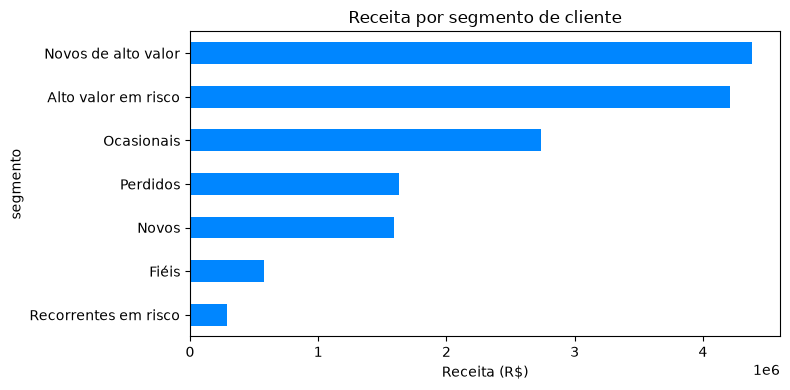

In [4]:
resumo["receita"].sort_values().plot.barh(figsize=(8, 4), color="#0086FF")
plt.title("Receita por segmento de cliente")
plt.xlabel("Receita (R$)")
plt.tight_layout()
plt.show()

In [5]:
import seaborn as sns

# Primeira compra de cada cliente único
base = rfm_base.copy()
base["mes_compra"] = base["data_compra"].dt.to_period("M")
base["mes_cohort"] = base.groupby("customer_unique_id")["data_compra"].transform("min").dt.to_period("M")
base["meses_apos"] = (base["mes_compra"] - base["mes_cohort"]).apply(lambda x: x.n)

# Clientes ativos por cohort e mês após a primeira compra
cohort = (base.groupby(["mes_cohort", "meses_apos"])["customer_unique_id"]
              .nunique().unstack(fill_value=0))

# Só cohorts com volume relevante (o início de 2017 tem poucos clientes)
cohort = cohort[cohort[0] >= 500]

retencao = cohort.div(cohort[0], axis=0).round(3)
retencao.iloc[:, :7]

meses_apos,0,1,2,3,4,5,6
mes_cohort,,,,,,,
2017-01,1.0,0.003,0.003,0.001,0.004,0.001,0.004
2017-02,1.0,0.002,0.003,0.001,0.004,0.001,0.002
2017-03,1.0,0.004,0.004,0.004,0.004,0.002,0.002
2017-04,1.0,0.006,0.002,0.002,0.003,0.003,0.004
2017-05,1.0,0.005,0.005,0.003,0.003,0.003,0.004
2017-06,1.0,0.005,0.004,0.004,0.003,0.004,0.004
2017-07,1.0,0.005,0.003,0.002,0.003,0.002,0.003
2017-08,1.0,0.007,0.003,0.003,0.003,0.005,0.003
2017-09,1.0,0.007,0.005,0.003,0.004,0.002,0.002


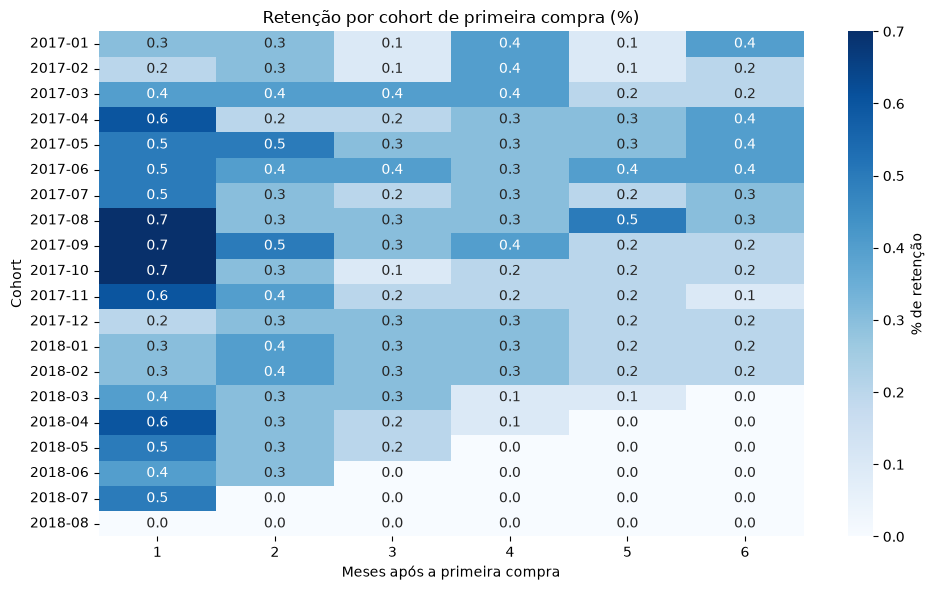

In [6]:
plt.figure(figsize=(10, 6))
sns.heatmap(retencao.iloc[:, 1:7] * 100, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% de retenção"})
plt.title("Retenção por cohort de primeira compra (%)")
plt.xlabel("Meses após a primeira compra")
plt.ylabel("Cohort")
plt.tight_layout()
plt.show()

In [7]:
import os
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv("../.env")
engine = create_engine(URL.create(
    "mysql+pymysql",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
))

rev = pd.read_sql("""
    SELECT r.order_id, r.review_score, r.review_comment_message AS texto,
           f.atrasou, f.dias_atraso
    FROM order_reviews r
    JOIN fato_entrega f ON f.order_id = r.order_id
    WHERE r.review_comment_message IS NOT NULL
""", engine)

print(rev.shape)
rev.sample(5, random_state=1)

(39094, 5)


,order_id,review_score,texto,atrasou,dias_atraso
18844,7b1b657e9cd1e1d807d0b89c08431139,5,"Super recomendo, pessoal responsavel e bem ate...",0,-13
3015,1329f69c4d3811f5a7bc6be850089a0d,5,"Adorei , alem de ter chegado o produto esperad...",0,-23
12880,53b3fc5e3b224d01407dd5acefd75a53,4,"Entrega rápida, antes da data.",0,-13
2106,0d21189c5494d8288ee358b3b24f85b4,5,atendeu o procurado preço e entrega,0,-8
35458,e78602addbd8567873e9ad519d11ad9c,1,Meu produto nao foi entregue.\r\n,1,51


In [9]:
import re
import unicodedata

def normaliza(t):
    t = unicodedata.normalize("NFKD", str(t).lower())
    return "".join(c for c in t if not unicodedata.combining(c))

rev["txt"] = rev["texto"].apply(normaliza)

temas["Atraso / não entregue"] = (
    r"atrasou|atrasad|atraso|demorou|demora|nao chegou|nao foi entregue|"
    r"nao recebi|nao entreguer|fora do prazo|apos o prazo|depois do prazo|passou do prazo"
)

for nome, padrao in temas.items():
    rev[nome] = rev["txt"].str.contains(padrao, regex=True)

print("Base: % de atrasados entre quem comentou:", round(100 * rev["atrasou"].mean(), 1))

resumo_temas = pd.DataFrame({
    "mencoes": {t: rev[t].sum() for t in temas},
    "nota_media": {t: round(rev.loc[rev[t], "review_score"].mean(), 2) for t in temas},
    "pct_em_atrasados": {t: round(100 * rev.loc[rev[t], "atrasou"].mean(), 1) for t in temas},
}).sort_values("mencoes", ascending=False)
resumo_temas

Base: % de atrasados entre quem comentou: 10.9


,mencoes,nota_media,pct_em_atrasados
Elogio à entrega,8237,4.68,1.9
Defeito / qualidade,3922,3.51,6.7
Atraso / não entregue,3708,1.87,53.0
Vendedor / atendimento,2178,3.03,15.7
Produto errado / diferente,1558,2.10,5.6
